# 02. 감정 분류 베이스라인 성능 — KcELECTRA × KOTE

**목적**: 일기 감정 분석(→ 행성 외형)의 첫 모델로, KOTE 44개 감정 다중 라벨 분류 베이스라인을 학습하고 성능을 확인한다.

- 학습은 노트북이 아니라 스크립트로 실행한다(시간이 오래 걸리고 GPU를 쓰므로):
  `.venv\Scripts\python ai\scripts\train_emotion_baseline.py` → 결과 `ai/outputs/emotion/<run_id>/`, 모델 `ai/checkpoints/emotion_baseline/<run_id>/`
- 이 노트북은 저장된 학습 결과를 읽어 **학습 곡선, test 성능, 라벨별 성능, 행성 그룹 단위 성능**을 확인하고, 가상 일기 예시로 추론을 시연한다.
- 설정: `ai/configs/emotion_baseline.json` (KcELECTRA-base v2021, max_length 256 + 동적 패딩, batch 32, lr 2e-5, BCE, bf16, 최대 10 epoch, 조기 종료)

**평가 원칙**: 모델 선택과 threshold 조정은 **validation에서만** 하고, test는 최종 보고에만 쓴다.

## 1. 환경과 학습 결과 불러오기

저장소 `.venv` 커널인지 먼저 점검한다(이 노트북은 PyTorch가 필요하다).

In [1]:
import os
import sys
import json
import platform
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 모두 지원)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(학습 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-train.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"


def rel(p) -> str:
    return Path(p).resolve().relative_to(P.repo_root).as_posix()

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """열별 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

from src.data.labels import load_label_names
from src.emotion import metrics as M
from src.emotion.planet_mapping import load_mapping

LABELS = load_label_names(P.configs / "kote_labels.json")
MAPPING = load_mapping(P.configs / "planet_mapping.json")

RUN_ID = "baseline_v2021_s42"   # KcELECTRA 베이스라인. None이면 가장 최근의 전체 학습(smoke 제외) 결과를 사용
EMO_OUT = P.ai_root / "outputs" / "emotion"
runs = sorted([p for p in EMO_OUT.iterdir() if p.is_dir() and not p.name.startswith("smoke_")
               and (p / "metrics.json").exists()], key=lambda p: p.stat().st_mtime)
if not runs:
    raise FileNotFoundError("학습 결과가 없습니다. 먼저 ai/scripts/train_emotion_baseline.py를 실행하세요.")
RUN = EMO_OUT / RUN_ID if RUN_ID else runs[-1]
info = json.loads((RUN / "metrics.json").read_text(encoding="utf-8"))
history = pd.read_csv(RUN / "history.csv")
probs = {s: np.load(RUN / f"{s}_probs.npy") for s in ("validation", "test")}
ytrue = {s: np.load(RUN / f"{s}_labels.npy") for s in ("validation", "test")}
TH = json.loads((RUN / "thresholds.json").read_text(encoding="utf-8"))
FIG = RUN / "figures"
print("run:", rel(RUN))

run: ai/outputs/emotion/baseline_v2021_s42


## 2. 학습 실행 정보

In [3]:
cfg = info["config"]
run_table = pd.Series({
    "모델": f"{cfg['model']['repo_id']} ({cfg['model']['revision_name']})",
    "파라미터 수": f"{info['n_params'] / 1e6:.1f}M",
    "데이터 (train/val/test)": " / ".join(f"{info['rows'][s]:,}" for s in ("train", "validation", "test")),
    "입력 길이": f"max_length {cfg['data']['max_length']} + 동적 패딩",
    "학습 설정": f"batch {cfg['train']['batch_size']}, lr {cfg['train']['learning_rate']}, "
                 f"warmup {cfg['train']['warmup_ratio']:.0%}, {cfg['train']['precision']}, seed {cfg['train']['seed']}",
    "실행 epoch / 최고 epoch": f"{info['epochs_run']} / {info['best_epoch']}",
    "학습 시간": f"{info['train_seconds'] / 60:.1f}분",
    "GPU / 최장 배치 메모리": f"{info['gpu']} / {info['peak_gpu_mem_longest_batch_gib']} GiB",
    "버전": ", ".join(f"{k} {v}" for k, v in info["versions"].items()),
}, name="값")
display(run_table.to_frame())

,값
모델,beomi/KcELECTRA-base (v2021)
파라미터 수,124.6M
데이터 (train/val/test),"40,000 / 5,000 / 5,000"
입력 길이,max_length 256 + 동적 패딩
학습 설정,"batch 32, lr 2e-05, warmup 10%, bf16, seed 42"
실행 epoch / 최고 epoch,9 / 6
학습 시간,49.9분
GPU / 최장 배치 메모리,NVIDIA GeForce RTX 4060 Ti / 0.977 GiB
버전,"python 3.13.5, torch 2.14.1+cu130, cuda 13.0, ..."


## 3. 학습 곡선

**해석 방법**: train loss가 계속 내려가는데 validation loss가 다시 오르면 과적합 신호다.
모델은 validation macro-F1(threshold 0.3, 논문과 같은 기준)이 가장 높은 epoch를 저장했다.

그림 저장: ai/outputs/emotion/baseline_v2021_s42/figures/learning_curve.png | 글꼴 누락 없음


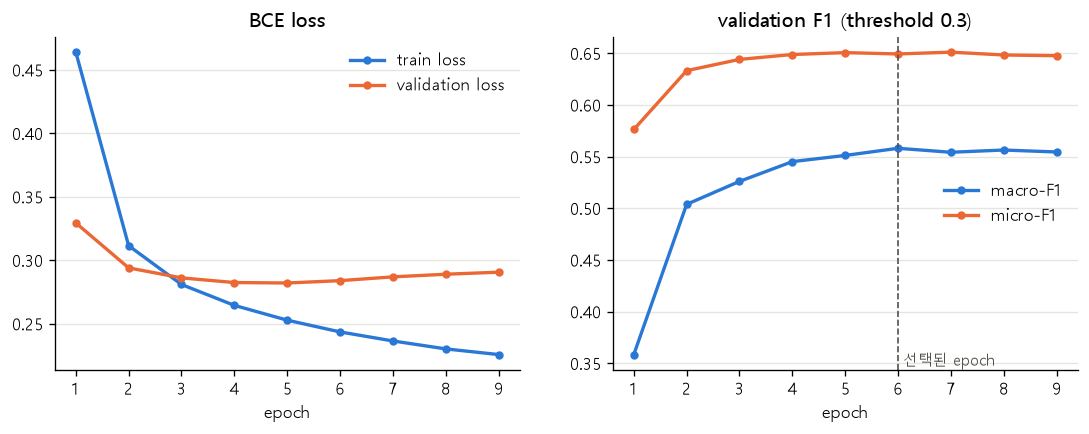

,epoch,train_loss,val_loss,val_macro_f1@0.3,val_micro_f1@0.3,val_macro_auc,epoch_sec
0,1,0.4639,0.3294,0.3585,0.5762,0.8059,446
1,2,0.3115,0.2940,0.5038,0.6331,0.8525,356
2,3,0.2809,0.2861,0.5260,0.6440,0.8629,357
3,4,0.2644,0.2824,0.5451,0.6488,0.8672,343
4,5,0.2528,0.2821,0.5511,0.6506,0.8689,359
5,6,0.2435,0.2839,0.5580,0.6493,0.8691,381
6,7,0.2364,0.2869,0.5542,0.6511,0.8687,338
7,8,0.2302,0.2890,0.5564,0.6483,0.8684,206
8,9,0.2257,0.2906,0.5545,0.6476,0.8678,206


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(history["epoch"], history["train_loss"], marker="o", ms=4, lw=2, color=SERIES[0], label="train loss")
ax.plot(history["epoch"], history["val_loss"], marker="o", ms=4, lw=2, color=SERIES[1], label="validation loss")
ax.set_title("BCE loss")
ax.set_xlabel("epoch")
ax.legend(frameon=False)
ax = axes[1]
ax.plot(history["epoch"], history["val_macro_f1@0.3"], marker="o", ms=4, lw=2, color=SERIES[0], label="macro-F1")
ax.plot(history["epoch"], history["val_micro_f1@0.3"], marker="o", ms=4, lw=2, color=SERIES[1], label="micro-F1")
ax.axvline(info["best_epoch"], color="#52514e", ls="--", lw=1)
ax.text(info["best_epoch"], ax.get_ylim()[0], " 선택된 epoch", color="#52514e", fontsize=9, va="bottom")
ax.set_title("validation F1 (threshold 0.3)")
ax.set_xlabel("epoch")
ax.legend(frameon=False)
for a in axes:
    a.grid(axis="y", color="#e4e4e0", lw=0.8)
    a.set_xticks(history["epoch"])
save_fig(fig, FIG / "learning_curve.png")
plt.show()
show_fmt(history, {c: "{:.4f}" for c in history.columns if c not in ("epoch", "epoch_sec")} | {"epoch_sec": "{:.0f}"}, index=False)

**결과 해석**

- train loss는 epoch마다 꾸준히 내려간다. validation loss는 epoch 5(0.2821)에서 가장 낮고, 이후 조금씩 오른다(epoch 9 0.2906). **약한 과적합**이 시작되었다는 신호다.
- validation macro-F1(threshold 0.3)은 epoch 6에서 0.558로 가장 높았다. 이후 3 epoch 동안 개선이 없어 epoch 9에서 조기 종료했고, **epoch 6 모델**을 저장했다.
- micro-F1은 epoch 4 이후 0.65 근처에서 거의 변하지 않는다. 빈발 라벨은 일찍 학습되고, 이후 epoch에서는 희소 라벨 성능(macro-F1)이 조금씩 오른 것으로 보인다.

## 4. Test 성능

threshold 전략 세 가지를 비교한다. 두 번째·세 번째는 **validation에서 정한 값**을 test에 그대로 적용한다.

| 전략 | 설명 |
|---|---|
| `paper_0.3` | 모든 라벨 0.3 (KOTE 논문 기준) |
| `global_tuned` | 모든 라벨 같은 값, validation macro-F1 최대 |
| `per_label_tuned` | 라벨별로 validation F1이 최대인 값 |

**지표 읽는 법**: macro-F1은 44개 라벨 F1의 단순 평균(희소 라벨도 같은 비중), micro-F1은 전체 예측을 합쳐 계산(빈발 라벨 비중 큼),
macro ROC-AUC는 threshold와 무관한 순위 성능이다. 참고로 KOTE 공식 README의 macro-F1은 0.56(논문 버전)·0.55(HF Trainer 버전)이다.

In [5]:
rows = []
for strat, by_split in info["metrics"].items():
    for split in ("validation", "test"):
        m = by_split[split]
        rows.append({"전략": strat, "split": split, "macro-F1": m["macro_f1"], "micro-F1": m["micro_f1"],
                     "weighted-F1": m["weighted_f1"], "samples-F1": m["samples_f1"],
                     "macro-P": m["macro_precision"], "macro-R": m["macro_recall"],
                     "macro ROC-AUC": m["macro_roc_auc"], "예측 라벨 수": m["mean_pred_labels"],
                     "정답 라벨 수": m["mean_true_labels"]})
perf = pd.DataFrame(rows)
perf.to_csv(RUN / "performance_summary.csv", index=False, encoding="utf-8-sig")
show_fmt(perf, {c: "{:.4f}" for c in perf.columns if c not in ("전략", "split", "예측 라벨 수", "정답 라벨 수")}
         | {"예측 라벨 수": "{:.2f}", "정답 라벨 수": "{:.2f}"}, index=False)
print("global_tuned threshold (validation에서 결정):", TH["global_tuned"])
pl = np.array(TH["per_label"])
print(f"per_label threshold 범위: {pl.min():.2f} ~ {pl.max():.2f} (중앙값 {np.median(pl):.2f})")
ref = cfg["reference"]
print(f"참고: KOTE README macro-F1 {ref['paper_macro_f1']} (논문 버전) / {ref['hf_trainer_version_macro_f1']} (HF Trainer 버전)")

,전략,split,macro-F1,micro-F1,weighted-F1,samples-F1,macro-P,macro-R,macro ROC-AUC,예측 라벨 수,정답 라벨 수
0,paper_0.3,validation,0.5580,0.6493,0.6438,0.6400,0.5255,0.6160,0.8691,9.67,7.87
1,paper_0.3,test,0.5570,0.6479,0.6424,0.6397,0.5235,0.6120,0.8708,9.65,7.93
2,global_tuned,validation,0.5596,0.6471,0.6435,0.6384,0.5127,0.6335,0.8691,10.10,7.87
3,global_tuned,test,0.5585,0.6460,0.6423,0.6385,0.5117,0.6290,0.8708,10.07,7.93
4,per_label_tuned,validation,0.5724,0.6463,0.6512,0.6380,0.5295,0.6367,0.8691,9.75,7.87
5,per_label_tuned,test,0.5671,0.6424,0.6467,0.6347,0.5277,0.6262,0.8708,9.68,7.93


global_tuned threshold (validation에서 결정): 0.28
per_label threshold 범위: 0.12 ~ 0.51 (중앙값 0.32)
참고: KOTE README macro-F1 0.56 (논문 버전) / 0.55 (HF Trainer 버전)


**결과 해석**

- **test macro-F1 0.557**(threshold 0.3)로, KOTE 공식 README의 0.56(논문 버전)·0.55(HF Trainer 버전)과 같은 수준이다. 조건이 완전히 같지는 않다. 논문은 토큰 무작위 교체·마스킹 증강, 512 고정 패딩을 썼고, 이 베이스라인은 증강 없이 256 동적 패딩을 썼다.
- validation에서 라벨별 threshold를 정해 test에 적용하면 macro-F1이 **0.567**(+0.010)로 오른다. 전체 공통 threshold 조정(0.28)의 이득은 +0.002로 작다.
- validation과 test 성능 차이가 작다(macro-F1 0.572 vs 0.567). threshold를 validation에서 정한 방식이 test에 잘 일반화된다.
- macro ROC-AUC 0.871: 라벨별 순위 성능은 양호하다. F1을 낮추는 주원인은 threshold보다 희소 라벨이다(5절).
- 모델은 샘플당 약 9.7개 라벨을 예측한다(정답 평균 7.9개). 재현율(0.61~0.63)이 정밀도(0.51~0.53)보다 높은 쪽으로 기울어 있어, 실제보다 감정을 조금 넓게 고른다.

## 5. 라벨별 성능

**목적**: 어떤 감정은 잘 맞히고 어떤 감정은 어려운지, 그리고 그것이 학습 데이터 빈도와 관련 있는지 본다(test, 라벨별 threshold 기준).

그림 저장: ai/outputs/emotion/baseline_v2021_s42/figures/per_label_f1.png | 글꼴 누락 없음


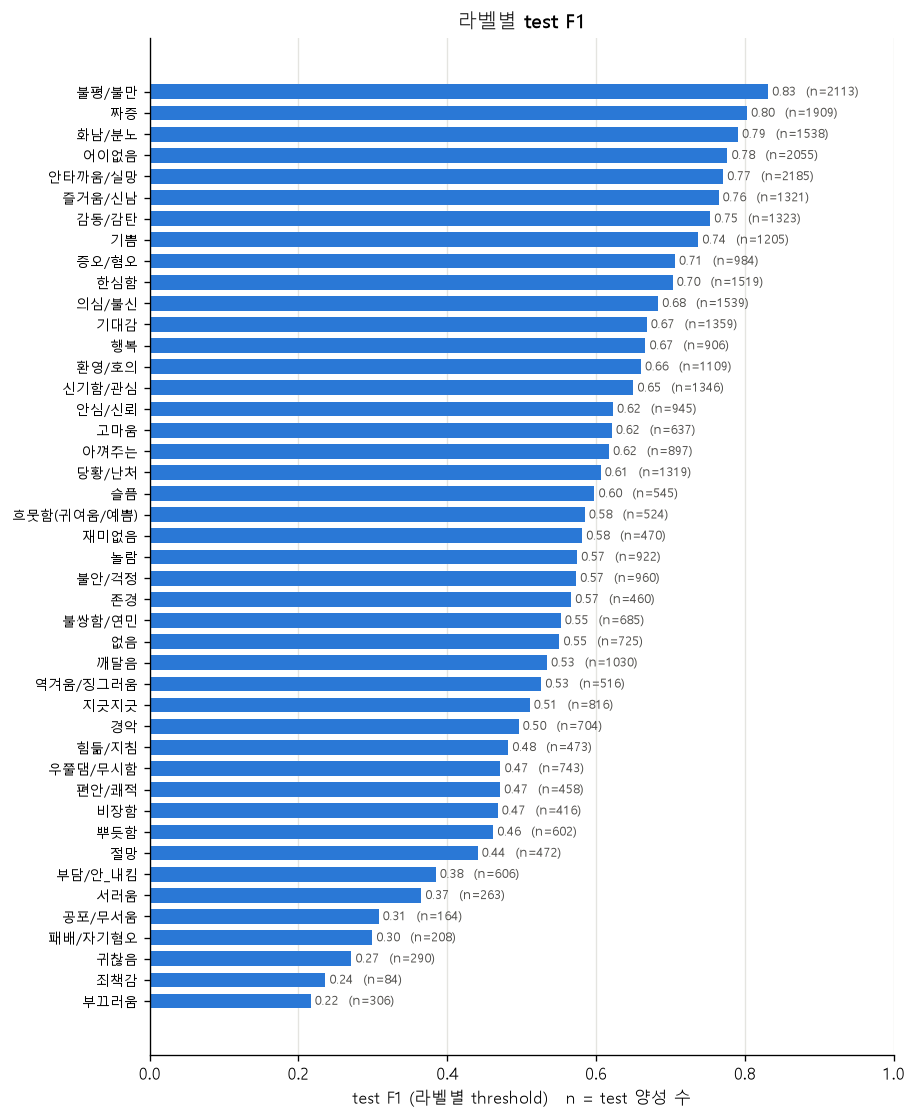

라벨별 F1과 train 양성 수의 Spearman 상관: 0.893
F1 상위 5: 불평/불만(0.83), 짜증(0.80), 화남/분노(0.79), 어이없음(0.78), 안타까움/실망(0.77)
F1 하위 5: 부끄러움(0.22, n=306), 죄책감(0.24, n=84), 귀찮음(0.27, n=290), 패배/자기혐오(0.30, n=208), 공포/무서움(0.31, n=164)
ROC-AUC 범위: 0.728 ~ 0.936


In [6]:
per = pd.read_csv(RUN / "per_label_test.csv", encoding="utf-8-sig")
dist = pd.read_csv(P.outputs_kote / "label_distribution.csv", encoding="utf-8-sig")
per["train_count"] = dist["count_train"].values
group_of = {lab: g["name"] for g in MAPPING["groups"] for lab in g["labels"]} | {MAPPING["neutral"]["label"]: "없음"}
per["group"] = per["label"].map(group_of)
order = per.sort_values("f1")

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(order["label"], order["f1"], color=SERIES[0], height=0.7)
for y, (f1, sup) in enumerate(zip(order["f1"], order["support_test"])):
    ax.text(f1 + 0.005, y, f"{f1:.2f}  (n={sup})", va="center", fontsize=7.5, color="#52514e")
ax.set_xlim(0, 1)
ax.set_xlabel("test F1 (라벨별 threshold)   n = test 양성 수")
ax.set_title("라벨별 test F1")
ax.grid(axis="x", color="#e4e4e0", lw=0.8)
ax.tick_params(axis="y", labelsize=8.5)
save_fig(fig, FIG / "per_label_f1.png")
plt.show()

rho = per[["f1", "train_count"]].corr(method="spearman").iloc[0, 1]
print(f"라벨별 F1과 train 양성 수의 Spearman 상관: {rho:.3f}")
print("F1 상위 5:", ", ".join(f"{r.label}({r.f1:.2f})" for r in per.nlargest(5, "f1").itertuples()))
print("F1 하위 5:", ", ".join(f"{r.label}({r.f1:.2f}, n={r.support_test})" for r in per.nsmallest(5, "f1").itertuples()))
print("ROC-AUC 범위:", f"{per['roc_auc'].min():.3f} ~ {per['roc_auc'].max():.3f}")

그림 저장: ai/outputs/emotion/baseline_v2021_s42/figures/f1_vs_frequency.png | 글꼴 누락 없음


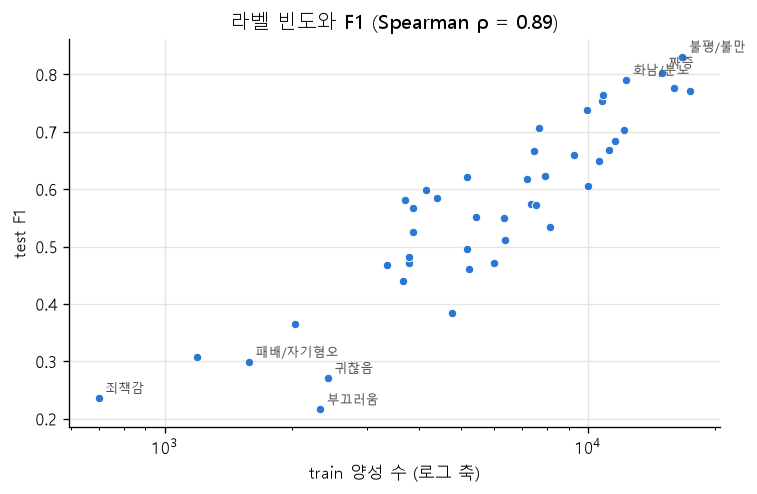

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(per["train_count"], per["f1"], s=26, color=SERIES[0], edgecolor="white", linewidth=0.6, zorder=3)
ax.set_xscale("log")
for r in pd.concat([per.nlargest(3, "f1"), per.nsmallest(4, "f1")]).itertuples():
    ax.annotate(r.label, (r.train_count, r.f1), xytext=(4, 3), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xlabel("train 양성 수 (로그 축)")
ax.set_ylabel("test F1")
ax.set_title(f"라벨 빈도와 F1 (Spearman ρ = {rho:.2f})")
ax.grid(color="#e4e4e0", lw=0.8)
save_fig(fig, FIG / "f1_vs_frequency.png")
plt.show()

**결과 해석**

- 라벨별 F1은 0.22(부끄러움)부터 0.83(불평/불만)까지 차이가 크다. 0.7 이상은 10개, 0.4 미만은 7개다.
- **F1과 train 양성 수의 Spearman 상관은 0.89**다. 성능 차이는 대부분 데이터 양으로 설명된다. 하위 라벨인 부끄러움, 죄책감, 귀찮음, 패배/자기혐오, 공포/무서움은 모두 희소 라벨이다.
- 희소 라벨은 threshold를 매우 낮게 잡아야 F1이 최대가 된다(죄책감 0.12, 부끄러움 0.13). threshold 0.3 기준 F1은 각각 0.06, 0.11에 그친다. 모델이 이 감정들에 확신이 낮은 확률만 낸다는 뜻이다.
- ROC-AUC는 0.73~0.94로, F1이 낮은 라벨도 순위로는 구분 신호가 있다. 데이터 보강이나 클래스 가중치로 개선할 여지가 있다.

## 6. 행성 그룹 단위 성능

행성 외형은 44개 라벨을 직접 쓰지 않고, `ai/configs/planet_mapping.json`의 **10개 감정 그룹 + ‘없음’**을 기준으로 정한다(03 노트북).
그래서 서비스 관점에서는 그룹 단위로 얼마나 맞는지가 중요하다.

1. **그룹 다중 라벨 F1**: 그룹 안 라벨이 하나라도 양성이면 그 그룹 양성으로 보고 F1을 계산
2. **주 그룹(행성 기본색) 일치율**: 원시 주석(`raw.json`)에서 평가자 선택 수가 가장 많은 그룹을 정답으로 두고,
   모델 확률이 가장 높은 그룹과 비교한다. 정답 그룹이 동점이면 그중 하나만 맞혀도 일치로 본다.

In [8]:
from src.data.kote_load import load_raw_annotations
from src.data.labels import rater_vote_counts

groups = MAPPING["groups"] + [{"id": "neutral", "name": "없음", "labels": [MAPPING["neutral"]["label"]]}]
gidx = [[LABELS.index(l) for l in g["labels"]] for g in groups]
gnames = [g["name"] for g in groups]
pl_thr = np.array(TH["per_label"])

yt, pt = ytrue["test"], probs["test"]
pred = M.binarize(pt, pl_thr)
Yg = np.stack([yt[:, ix].max(1) for ix in gidx], 1)
Pg = np.stack([pred[:, ix].max(1) for ix in gidx], 1)
gc = M.per_label_counts(Yg, Pg)
group_perf = pd.DataFrame({"group": gnames, "labels": [len(ix) for ix in gidx], "test 양성 비율": Yg.mean(0),
                           "precision": gc["precision"], "recall": gc["recall"], "F1": gc["f1"]})
show_fmt(group_perf, {"test 양성 비율": "{:.1%}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"}, index=False)
print(f"그룹 macro-F1: {gc['f1'].mean():.4f}  (라벨 macro-F1: {info['metrics']['per_label_tuned']['test']['macro_f1']:.4f})")

# 주 그룹 일치율 (원시 주석 기준 정답)
raw = load_raw_annotations(P.raw_kote)
test_ids = pd.read_csv(RUN / "test_ids.csv", dtype=str)["ID"].tolist()
name_to_id = {n: i for i, n in enumerate(LABELS)}
votes = np.stack([rater_vote_counts(raw[i]["labels"], name_to_id, len(LABELS)) for i in test_ids])
Vg = np.stack([votes[:, ix].max(1) for ix in gidx], 1)      # 그룹별 최다 선택 인원
Sg = np.stack([pt[:, ix].max(1) for ix in gidx], 1)         # 그룹 점수 = 그룹 내 최대 확률
true_top = Vg == Vg.max(1, keepdims=True)                  # 동점 허용 정답 집합
pred_rank = np.argsort(-Sg, 1)
top1 = true_top[np.arange(len(pt)), pred_rank[:, 0]]
top2 = top1 | true_top[np.arange(len(pt)), pred_rank[:, 1]]
rand_base = (true_top.sum(1) / len(groups)).mean()
print(f"주 그룹 일치율 top-1: {top1.mean():.3f} | top-2 안에 포함: {top2.mean():.3f} | 무작위 기준: {rand_base:.3f}")
print(f"정답 주 그룹이 동점인 샘플 비율: {(true_top.sum(1) > 1).mean():.3f}")
group_perf.to_csv(RUN / "group_performance_test.csv", index=False, encoding="utf-8-sig")

,group,labels,test 양성 비율,precision,recall,F1
0,기쁨·즐거움,5,37.7%,0.845,0.806,0.825
1,감사·애정,5,41.6%,0.827,0.818,0.822
2,평온·안심,2,22.1%,0.629,0.658,0.643
3,기대·호기심,5,56.3%,0.764,0.857,0.808
4,분노·불만,5,58.3%,0.893,0.884,0.889
5,혐오·불신,5,52.4%,0.803,0.865,0.833
6,슬픔·상실,5,51.1%,0.774,0.826,0.799
7,불안·당황,4,42.9%,0.656,0.790,0.717
8,지침·무기력,4,28.1%,0.584,0.610,0.597
9,부끄러움·자책,3,10.3%,0.283,0.406,0.334


그룹 macro-F1: 0.7107  (라벨 macro-F1: 0.5671)


주 그룹 일치율 top-1: 0.676 | top-2 안에 포함: 0.858 | 무작위 기준: 0.125
정답 주 그룹이 동점인 샘플 비율: 0.278


**결과 해석**

- 행성 그룹 단위 macro-F1은 **0.711**로, 라벨 단위(0.567)보다 크게 높다. 비슷한 감정끼리의 혼동은 같은 그룹 안에서 상쇄되기 때문이다.
- 분노·불만(0.89), 혐오·불신(0.83), 기쁨·즐거움(0.83), 감사·애정(0.82), 기대·호기심(0.81), 슬픔·상실(0.80)은 0.8 이상이다. **부끄러움·자책은 0.33**으로 가장 낮고, 지침·무기력(0.60)과 평온·안심(0.64)도 낮은 편이다.
- **행성 기본색 일치율**: 평가자 투표가 가장 많은 그룹을 정답으로 볼 때, 모델이 고른 1순위 그룹의 일치율은 **67.6%**, 2순위 안 포함은 **85.8%**다(무작위 기준 12.5%). 정답 그룹이 동점인 경우가 27.8%라 KOTE 자체도 ‘하나의 주 감정’이 모호한 댓글이 많다.
- 따라서 서비스 관점에서 기본색은 대체로 맞고, 틀려도 2순위 감정(보조색)에 들어가는 경우가 많다.

## 7. 가상 일기 추론 시연

`ai/configs/demo_diaries.json`의 문장은 **개발자가 직접 쓴 가상 일기**다(실제 사용자 일기·KOTE 원문 아님).
`intended`는 작성자가 의도한 감정이며 정답 라벨이 아니다. 학습 데이터(온라인 댓글)와 문체가 다른 일기 문장에서 모델이 그럴듯하게 반응하는지 정성적으로 본다.

In [9]:
from src.emotion.predict import EmotionPredictor

predictor = EmotionPredictor(P.repo_root / info["checkpoint_dir"])
demo = load_json(P.configs / "demo_diaries.json")["diaries"]
demo_probs = predictor.predict_proba([d["text"] for d in demo])
np.save(RUN / "demo_probs.npy", demo_probs)
rows = []
for d, p in zip(demo, demo_probs):
    top = np.argsort(-p)[:5]
    rows.append({"id": d["id"], "의도": d["intended"],
                 "상위 5개 감정 (확률)": ", ".join(f"{LABELS[j]} {p[j]:.2f}" for j in top),
                 "threshold 통과 수": int((p >= pl_thr).sum()), "없음": round(float(p[LABELS.index('없음')]), 2)})
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(rows))
print("device:", predictor.device)

,id,의도,상위 5개 감정 (확률),threshold 통과 수,없음
0,d01,joy,"기쁨 0.98, 즐거움/신남 0.95, 행복 0.94, 감동/감탄 0.70, 고마움 0.61",8,0.01
1,d02,warmth,"기쁨 0.93, 고마움 0.92, 행복 0.90, 감동/감탄 0.86, 즐거움/신남 0.50",9,0.01
2,d03,calm,"기쁨 0.96, 즐거움/신남 0.94, 행복 0.92, 편안/쾌적 0.52, 감동/감탄 0.51",5,0.05
3,d04,curiosity,"기대감 0.96, 신기함/관심 0.94, 감동/감탄 0.90, 즐거움/신남 0.79, 환영/호의 0.74",7,0.04
4,d05,anger,"짜증 0.96, 화남/분노 0.94, 불평/불만 0.91, 어이없음 0.58, 안타까움/실망 0.40",5,0.01
5,d06,sadness,"슬픔 0.96, 안타까움/실망 0.79, 불쌍함/연민 0.66, 절망 0.46, 불안/걱정 0.27",4,0.01
6,d07,anxiety,"불안/걱정 0.82, 당황/난처 0.23, 의심/불신 0.21, 기대감 0.20, 안타까움/실망 0.18",1,0.03
7,d08,fatigue,"힘듦/지침 0.93, 짜증 0.76, 지긋지긋 0.71, 슬픔 0.70, 서러움 0.65",15,0.06
8,d09,shame,"슬픔 0.95, 안타까움/실망 0.84, 불쌍함/연민 0.75, 절망 0.71, 힘듦/지침 0.70",10,0.07
9,d10,contempt,"불평/불만 0.96, 안타까움/실망 0.95, 의심/불신 0.94, 어이없음 0.94, 화남/분노 0.92",17,0.01


device: cuda


**결과 해석**

- 개발자가 쓴 가상 일기 12개에 대한 정성 점검이다. 수치 평가가 아니다.
- 기쁨(d01), 기대(d04), 분노(d05), 슬픔(d06), 불안(d07), 지침(d08)은 의도한 감정이 1순위로 나온다.
- 고마움(d02)은 고마움 0.92가 기쁨 0.93과 거의 같다. 편안함(d03)은 편안/쾌적 0.52로, 기쁨 계열보다 낮게 나온다. 긍정 일기는 기쁨으로 쏠리는 경향이 있다.
- 자책(d09)은 슬픔·안타까움으로 나오고 부끄러움·죄책감은 상위에 없다. 5절의 희소 라벨 문제가 일기에서도 그대로 나타난다.
- 담담한 일기(d11)는 ‘없음’ 0.36으로 다른 문장보다 높지만, 힘듦/지침 0.65가 더 높다. 기쁨과 아쉬움이 섞인 일기(d12)는 아쉬움·슬픔만 잡히고 즐거움은 놓친다.
- KOTE는 온라인 댓글 데이터라 일기 문체와 다르다. 실제 일기(동의받은 소량)로 검증하는 것이 다음 과제다.

## 8. 결론

- **베이스라인 성능**: test macro-F1 0.557(threshold 0.3) / 0.567(라벨별 threshold), micro-F1 0.64, macro ROC-AUC 0.871. KOTE 공식 README 수치(0.55~0.56)와 같은 수준으로 재현했다.
- **행성 관점 성능**: 10개 감정 그룹 단위 macro-F1 0.711, 행성 기본색(주 그룹) 일치율 67.6%(2순위 안 85.8%).
- **약점**: 희소 감정(부끄러움, 죄책감, 귀찮음, 패배/자기혐오, 공포/무서움)의 F1이 0.22~0.31로 낮다. 긍정 일기가 ‘기쁨’ 쪽으로 쏠린다. 섞인 감정 중 긍정 쪽을 놓치는 경우가 있다.
- **다음 개선 후보**(효과는 검증 필요):
  1. 희소 라벨 보강: 클래스 가중치 BCE 또는 focal loss
  2. `raw.json` 평가자 선택 수를 soft label로 쓰기
  3. 논문의 토큰 교체·마스킹 증강
  4. 실제 일기 소량으로 도메인 검증 후 미세조정